# 07 视频处理、媒资绑定与门户部署


## 资料来源与当天目标

本篇对应百度网盘 14 天目录中的 **day07 视频处理 部署门户**。第 06 篇已经完成分片上传、合并文件与 XXL-JOB 接入，本篇继续完成视频从“上传成功”到“可以播放”的后台链路，再把视频绑定到课程计划，部署用于展示课程的门户页面。

主要资料：

- `第3章媒资管理模块v3.1.docx`：7.1 视频需求与工具、7.3—7.9 视频任务处理、8 绑定媒资。复用之前下载的完整讲义；本日网盘资料中也列有同名文档。
- `课程发布-部署门户文档.docx`：网盘文档预览共 23 页，重点核对 2.3.1—2.3.4 的门户、课程详情、文件服务器与播放页面；补充其 FreeMarker 快速入门。
- `xcplus_media.sql` 与前面下载的 Nacos 配置：静态核对任务表、媒资桶、服务端口。
- 已下载的 day06 代码包中的 `Mp4VideoUtil.java`、`VideoUtil.java`：用于说明课程视频工具的实际行为。

**来源边界：**day07 项目代码包、门户 ZIP 与独立 `nginx.conf.zip` 的下载未确认成功，因此本篇业务实现依据讲义整理，门户配置依据可读的原文预览核对；不宣称逐文件核验这些 ZIP。代码块中的“校正”“补充”属于学习整理，不代表课程源码已经实现。本次只编写笔记，未运行课程项目、FFmpeg、Nginx 或课程 SQL。

学完应能解释：为什么转码适合异步任务；分片与任务认领各自解决什么问题；任务状态、数据库事务与 MinIO 文件之间如何衔接；课程计划如何绑定媒资；浏览器如何经 Nginx 加载页面、图片和视频。


## 1. 今天要打通的业务链路

上传视频时，用户主要关心文件是否成功保存。转码可能持续几分钟，不能让上传接口一直等待，否则容易超时，也会占用接口线程。因此课程把耗时处理交给后台执行器。

```text
前端分片上传 → MinIO 保存源视频 → media_files 记录源文件
                                  ↓
                            media_process 创建任务
                                  ↓
XXL-JOB 定期调度 → 分片取任务 → 原子认领 → 下载 → FFmpeg 转码
                                  ↓
                            MinIO 保存 MP4
                                  ↓
更新播放 URL → 成功任务归档 → 课程计划绑定媒资 → 门户播放
```

这里有三个不同的成功条件：**上传成功、处理成功、业务上可用**。源 AVI 已经入库，不代表 MP4 已经生成；MP4 已生成，也不代表它已审核或已经绑定某个课程小节。

第 07 天门户部分的目标是静态页面可以打开、样式与图片正常、测试视频可以播放。正式课程预览、审核和发布的完整业务，继续在后面的课程发布笔记中展开。


## 2. 视频容器与编码格式

视频文件通常包含视频流、音频流、字幕、时长等信息。**容器格式**负责把这些内容组织在一个文件中；**编码格式**负责压缩和还原具体的音视频数据。

| 概念 | 常见例子 | 应该怎样理解 |
| --- | --- | --- |
| 容器 | MP4、AVI、MKV | 相当于装音视频流的文件结构 |
| 视频编码 | H.264、H.265、VP9、AV1 | 决定视频数据如何压缩和解码 |
| 音频编码 | AAC、MP3、Opus | 决定音频数据如何压缩和解码 |
| 像素格式 | yuv420p 等 | 影响编码器、解码器和播放器的兼容性 |

浏览器是否能播放，取决于容器、编码、浏览器和设备能力等因素。课程使用 MP4 输出，并通过 `libx264` 编码视频，这是常见的兼容性方案。

把 `lesson.avi` 重命名为 `lesson.mp4` 只改变文件名，文件内部的数据没有改变。即使文件原来就是 MP4，如果内部编码不受目标浏览器支持，也可能仍需转码。

课程目前只对 AVI 建立任务，这是教学范围的简化。生产系统通常还要探测真实媒体信息，而不能只用扩展名判断兼容性。


## 3. FFmpeg 的基本使用

FFmpeg 是音视频处理工具，可以完成转码、抽取音轨、截图、改变分辨率等工作。官方入口：[FFmpeg 下载](https://www.ffmpeg.org/download.html)；命令说明：[FFmpeg 文档](https://ffmpeg.org/ffmpeg.html)。

讲义写的版本检查命令是 `ffmpeg -v`。**校正：**`-v` 用来设置日志级别，查看版本应使用：

```powershell
ffmpeg -version
ffmpeg -i "1.avi" "1.mp4"
ffmpeg -i "1.avi" -r 1 -f image2 "image-%03d.jpeg"
ffmpeg -i "1.avi" "1.mp3"
ffmpeg -i "1.avi" "1.gif"
```

这些分别表示查看版本、转换文件、按每秒 1 帧抽图、提取音频和生成 GIF。第二条依赖 FFmpeg 的默认编码选择；学习时还应知道如何明确指定参数。

**补充示例：**下面将视频编码为 H.264、音频编码为 AAC，并约束为常见像素格式。缩放保持宽高比，`-2` 让高度自动计算为偶数；它不是课程原命令。

```powershell
ffmpeg -i "lesson.avi" -c:v libx264 -pix_fmt yuv420p -vf "scale=1280:-2" -c:a aac -b:a 128k -movflags +faststart -y "lesson.mp4"
```

`+faststart` 把 MP4 的索引信息移到文件前部，有利于网络播放尽早开始。`-y` 会覆盖已有输出；实际任务应使用独立临时路径，避免覆盖其他任务的文件。

转码是重新编码；如果源编码已经兼容，有时可以用 `-c copy` 重封装以节省时间，但它不会修复不兼容的编码。不要把重封装与转码混为一谈。


## 4. 课程视频工具类的实际行为

讲义把工具类放在 `xuecheng-plus-base` 工程的 `com.xuecheng.base.utils` 包中。`Mp4VideoUtil` 继承 `VideoUtil`，前者负责生成 MP4，后者提供获取时长和等待进程的方法。

```java
// 调用示例；ffmpegPath 应从配置中取得。
File output = File.createTempFile("xuecheng-video-", ".mp4");
Mp4VideoUtil tool = new Mp4VideoUtil(
        ffmpegPath,
        source.getAbsolutePath(),
        task.getFileId() + ".mp4",
        output.getAbsolutePath());
String result = tool.generateMp4();
boolean success = "success".equals(result);
```

**容易读错的参数：**构造方法第四个参数名为 `mp4folder_path`，但实际被直接加入 FFmpeg 命令作为输出参数，所以这里传的是**完整输出文件路径**，不是输出目录。

代码包中的 `generateMp4()` 使用 `ProcessBuilder` 参数列表启动进程，合并标准输出与错误输出，调用 `waitFor(p)`，最后通过 `check_video_time(source,target)` 判断时长，成功返回字符串 `"success"`。它采用的主要参数是：

```text
-i 源文件 -c:v libx264 -y -s 1280x720 -pix_fmt yuv420p
-b:a 63k -b:v 753k -r 18 输出文件
```

固定 `1280×720` 可能改变原画面比例，固定帧率和码率也可能损失质量，应理解为演示参数。

父类还有几处需要校正：

- `check_video_time()` 在检查 `null` 之前就执行 `substring()`，探测失败时可能发生空指针；没有小数点也可能越界。
- 时长被截到整秒再比较，只能做粗略检查，不能保证编码、画面和音频都正确。
- `waitFor()` 读取错误流的循环实际写成了 `in.read()`；当前调用合并了错误流，但通用方法仍存在错误。
- 方法记录了退出码，却没有用它判定转码结果；超时返回 `"error"` 也没有销毁子进程。
- 以字节转 `char` 拼日志可能破坏多字节文本；无限累积日志会增加内存占用。

**补充：**实际处理应检查退出码、输出文件非空，并用 `ffprobe` 获取可解析的时长与流信息。探测命令和转码命令的退出语义不同：单独 `ffmpeg -i input` 没有输出文件时，即使打印了媒体信息也可能返回非零退出码，不能直接套用转码成功规则。


## 5. 视频处理的整体方案

讲义把上传入口和后台处理分开：媒资 API 接收请求、保存文件与元信息；独立任务执行器执行转码，XXL-JOB 管理周期性调度。

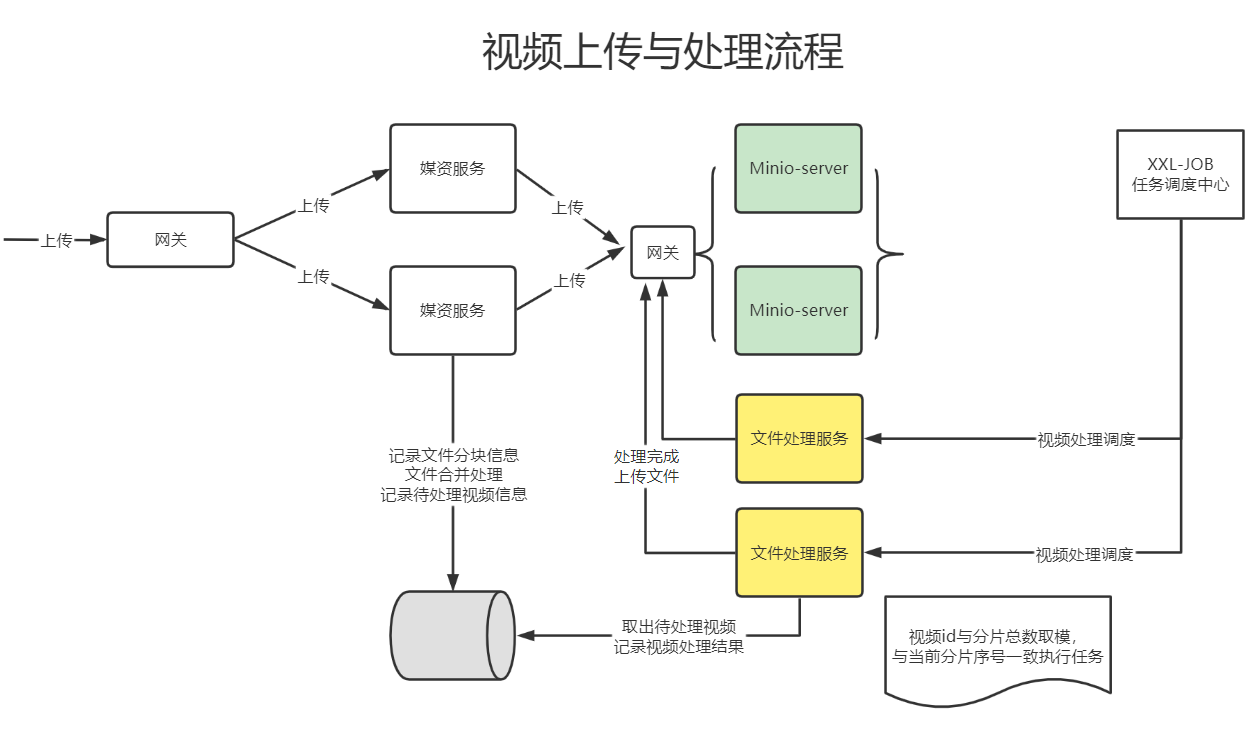

上图中的文件处理服务是任务执行器；网关、媒资 API 和 MinIO 各自承担不同职责。增加执行器实例能够分担任务，但前提是取任务和认领任务的逻辑支持多实例。

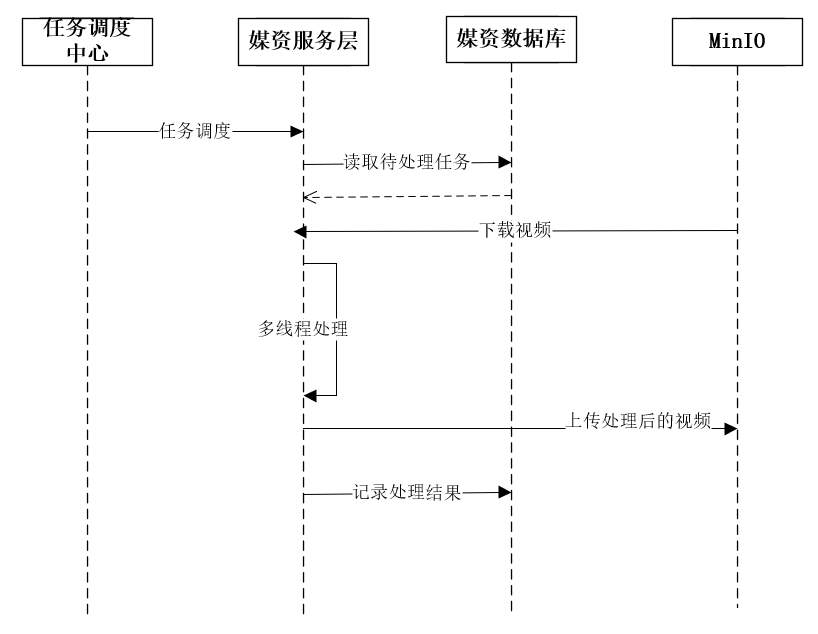

一次处理包含多个阶段：读取任务、下载源视频、本地转码、上传结果、保存处理状态。失败可能发生在任何阶段，不能只判断 `generateMp4()` 的返回值。

数据库保存任务的价值在于：请求结束后任务仍然存在；进程重启后可以继续查询；失败次数和错误原因可追踪。它并不自动保证每个任务只执行一次，后面仍要增加原子认领、幂等与补偿。


## 6. 三张表与任务状态

| 表 | 职责 | 关键字段 |
| --- | --- | --- |
| `media_files` | 源文件元信息以及当前业务访问地址 | `id/file_id`、`bucket`、`file_path`、`url` |
| `media_process` | 活动任务，包括等待、失败和处理中任务 | `id`、`file_id`、`status`、`fail_count`、`errormsg` |
| `media_process_history` | 保存成功归档任务 | 任务字段、完成时间、输出 URL |

`media_process.id` 是自增的 **Long 任务 ID**；`file_id` 是上传源文件的 MD5 字符串。任务 ID 用于分片、认领和状态更新，文件 ID 用于关联媒资和生成对象路径，两者不是一个概念。

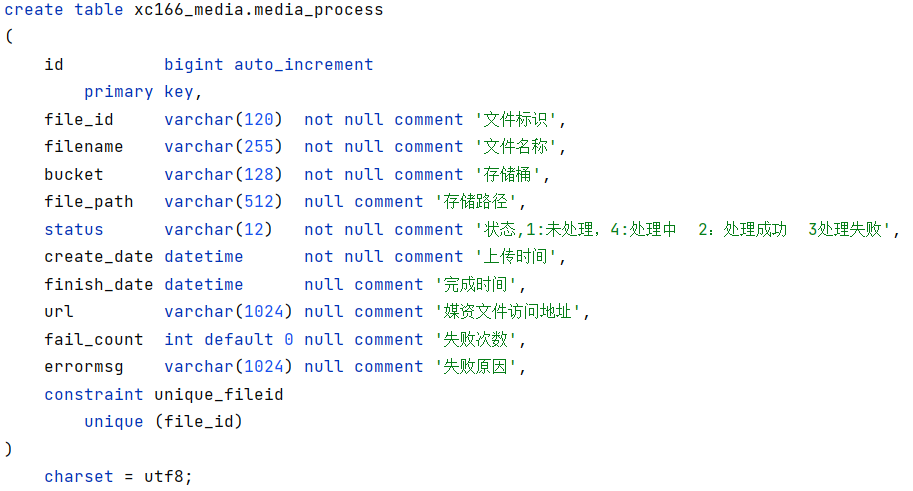

原 SQL 文件的状态注释列出 1、2、3，讲义处理代码还使用 4，因此应按下表理解：

| 状态 | 含义 | 正常流转 |
| --- | --- | --- |
| `1` | 未处理 | 认领成功后变为 `4` |
| `4` | 处理中 | 成功变 `2` 并归档，失败变 `3` |
| `3` | 处理失败 | 失败次数未达阈值时可以再次认领 |
| `2` | 处理成功 | 移入历史表后从活动表删除 |

活动表对 `file_id` 有唯一索引。同一个源文件不能同时无限创建相同活动任务。历史表与活动表字段相近，但原 SQL 的列顺序、索引和非空约束并不完全一致，归档时要显式映射或按实体属性复制，不能盲目 `INSERT ... SELECT *`。

**注意：**原表没有执行开始时间、租约或持有者字段。`create_date` 表示创建/上传时间，不能拿它代替某次实际认领时间来判断任务超时。


## 7. 上传成功后创建待处理任务

课程在 `addMediaFilesToDb()` 中保存媒资信息，并调用 `addWaitingTask(mediaFiles)`。只对 MIME 类型 `video/x-msvideo` 的 AVI 创建任务，初始状态为 `1`，失败次数为 `0`。

```java
// 按讲义思路整理的关键片段；省略普通媒资字段赋值。
private void addWaitingTask(MediaFiles mediaFiles) {
    String filename = mediaFiles.getFilename();
    int dot = filename == null ? -1 : filename.lastIndexOf('.');
    if (dot < 0) {
        return;
    }
    String mimeType = getMimeType(filename.substring(dot));
    if (!"video/x-msvideo".equals(mimeType)) {
        return;
    }
    MediaProcess task = new MediaProcess();
    BeanUtils.copyProperties(mediaFiles, task);
    task.setId(null); // 自增任务主键，不使用媒资的字符串 ID
    task.setFileId(mediaFiles.getFileId());
    task.setStatus("1");
    task.setFailCount(0);
    int rows = mediaProcessMapper.insert(task);
    if (rows != 1) {
        throw new IllegalStateException("创建视频处理任务失败");
    }
}
```

上面保留课程思路，补充了文件名判断和插入行数检查。`MediaFiles` 没有 MIME 属性，课程通过文件名扩展名调用 `getMimeType()` 得到 MIME；不要凭空给实体增加一个不存在的 getter。原媒资插入处以 `insert < 0` 判断失败，通常应校正为 `<= 0` 或要求恰好更新 1 行。

媒资记录和任务记录应由同一个本地数据库事务提交。若方法在同一个对象内部直接调用，不能假定内部方法上的 `@Transactional` 一定产生代理拦截；应让外部调用的业务入口开启事务。

MinIO 对象上传不属于数据库事务。对象成功、数据库失败时可能留下孤立文件，需要重试或定期清理。反过来，数据库记录提交后也不能仅凭记录断言源对象真实存在。

重复上传应结合活动任务唯一索引、媒资处理状态和业务幂等判断。任务已经成功归档后，再次收到上传请求，不应无条件重建转码任务。依据扩展名得到的 MIME 也不能替代文件内容探测。


## 8. XXL-JOB 分片查询任务

XXL-JOB 分片广播会给执行器传递 `shardIndex` 与 `shardTotal`。它不会替业务查询数据，需要执行器把参数应用到 SQL。

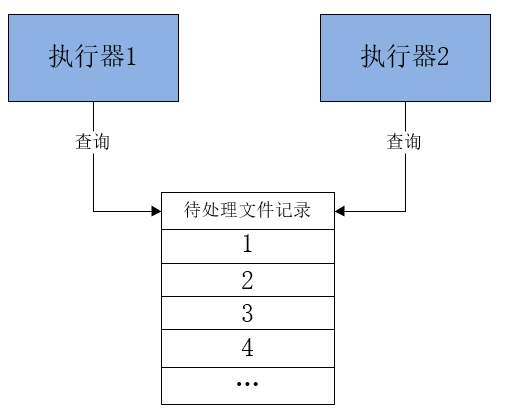

讲义的分片条件为任务主键对总分片数取模：

```sql
SELECT *
FROM media_process t
WHERE t.id % #{shardTotal} = #{shardIndex}
  AND (t.status = '1' OR t.status = '3')
  AND t.fail_count < 3
LIMIT #{count};
```

两个执行器时，分片 0 处理偶数 ID，分片 1 处理奇数 ID。这里使用任务主键，不是源文件 MD5。

```java
int shardIndex = XxlJobHelper.getShardIndex();
int shardTotal = XxlJobHelper.getShardTotal();
List<MediaProcess> tasks = mediaFileProcessService
        .getMediaProcessList(shardIndex, shardTotal, batchSize);
```

Service 的参数顺序是 `(shardIndex, shardTotal, count)`；讲义 Mapper 方法的顺序是 `(shardTotal, shardIndex, count)`，调用时不能直接照搬顺序。Mapper 参数应使用明确的 `@Param` 名称。

**补充：**可以在 `LIMIT` 前增加 `ORDER BY t.id`，并校验 `shardTotal > 0`、`0 <= shardIndex < shardTotal`、`count` 有合理上限。分片只减少当前调度中的任务重叠；实例数变化、上一次任务未结束和重复触发，仍可能让多个线程拿到相同候选任务。


## 9. 用原子更新认领任务

查询到一条任务，只说明它当时满足查询条件，并不代表当前线程已经拥有执行权。两个线程可能同时查到 `status=1`，随后一起转码，所以认领必须交给数据库的一条条件更新。

```sql
UPDATE media_process m
SET m.status = '4'
WHERE m.id = #{id}
  AND (m.status = '1' OR m.status = '3')
  AND m.fail_count < 3;
```

```java
public boolean startTask(Long id) {
    int rows = mediaProcessMapper.startTask(id);
    return rows == 1;
}
```

同一任务只能由将状态从 `1/3` 改成 `4` 的线程继续执行。其他线程更新行数为 0，应直接跳过。只写 `WHERE id = ?` 而没有状态条件，无法证明“抢占成功”。

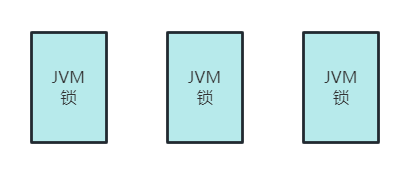

`synchronized` 的锁在单个 JVM 内，两个执行器各有自己的锁，不能互相排斥。

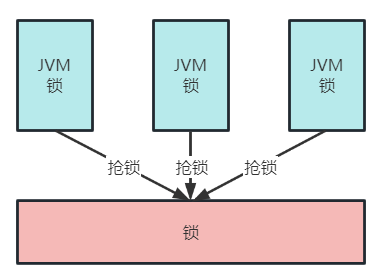

课程利用数据库中的共享状态完成任务认领。这里并非给整段转码过程加一个长事务，而是先用短 SQL 取得执行权，再在数据库事务之外做下载和转码。

讲义还介绍 Redis 和 ZooKeeper 方案：Redis 可通过 `SET ... NX` 原子创建锁键，ZooKeeper 可以用临时顺序节点及监听组织锁。实现这些方案时仍要考虑持有者、有效期、异常释放和业务幂等，不能只写一句“用分布式锁”就认为转码已可靠。

课程称状态条件更新为乐观锁思路：先尝试修改，条件不满足则认领失败；它没有让 worker 先持有一把长时间的排他锁。数据库执行 UPDATE 时仍会使用必要的行级锁，这与应用层的乐观并发判断并不矛盾。悲观锁则是在操作前先取得排他权，例如事务中的 `SELECT ... FOR UPDATE`；不适合把几分钟的转码直接包在长数据库锁事务中。

**分片与认领的关系：**分片减少候选任务重叠；条件更新决定实际谁能处理；结果提交校验与幂等保障状态一致。前一个环节不能代替后一个环节。


## 10. 保存失败结果

课程接口 `saveProcessFinishStatus(taskId,status,fileId,url,errorMsg)` 保存处理结果。失败时使用状态 `3`，更新错误原因并增加失败次数，任务保留在活动表中。

```text
下载失败 / 转码失败 / 上传失败
             ↓
media_process.status = 3
media_process.fail_count = 原值 + 1
media_process.errormsg = 本次错误原因
             ↓
下次调度重新查询，前提是 fail_count < 3
```

**重试次数要看 SQL：**初始 `fail_count=0`，每次失败加 1；当值变成 3 后不再自动选中，所以是累计最多 3 次失败，并不是“第一次处理失败后再重试 3 次，总计 4 次”。成功不会继续累计失败。

讲义先读取任务，再用 Java 计算 `failCount + 1`。若重复回调或并发提交失败结果，可能丢失更新。**补充方向：**在数据库中执行 `fail_count = fail_count + 1`，同时校验任务仍处于处理中且属于本次执行。

错误信息应记录失败阶段、任务 ID、源对象位置及 FFmpeg 日志摘要；不要只写“失败”，也不要无限保存整个进程日志。结果保存方法本身抛异常时，任务可能仍是 `4`，需要补偿流程兜底。


## 11. 保存成功结果与归档事务

成功的顺序是先把 MP4 上传到 MinIO，再开启数据库事务保存结果。课程成功分支包括：

1. 查找活动任务，不存在则返回。
2. 更新对应 `media_files.url`，使业务访问地址指向新 MP4。
3. 更新任务的 `url`、状态 `2`、`finish_date`。
4. 将任务属性复制到 `MediaProcessHistory` 并插入历史表。
5. 删除活动任务。

这几个数据库操作应在同一个 `@Transactional` 方法里完成，任何一步失败应回滚，避免“活动任务没了、历史记录却没保存”。必要操作应检查更新行数，不能仅凭没有抛异常就认为全部成功。

课程原实现主要更新媒资的 **播放 URL**。源文件的 `file_path`、文件名、文件大小仍可能记录原始 AVI；`file_id` 仍是原 AVI 的 MD5。不要把这个 MD5 描述为转码后 MP4 的摘要，也不要假定原文件已经被覆盖。

```text
源对象：video/a/b/{源文件MD5}/{源文件MD5}.avi
结果对象：video/a/b/{源文件MD5}/{源文件MD5}.mp4
媒资记录：仍代表该源文件，url 更新为结果访问地址
```

转码后对象内容不同，如需校验结果文件完整性，应另存结果摘要、实际大小及媒体信息。

原实现对任意非 `3` 状态都进入成功分支，这个判断过宽；还没有验证本次结果提交者是不是当前持有者。**补充：**明确只接受合法的成功/失败状态，校验 `status=4`、执行版本或持有者令牌，阻止旧线程覆盖新结果。

MinIO 上传与数据库提交不是一个原子事务。MP4 上传成功而数据库提交失败时，下一次处理可能重复上传；可以使用确定性的对象路径并结合执行版本、结果检查和清理任务做补偿。任务不存在后直接返回有助于重复提交幂等，但仍需区分“确实已成功归档”和“数据异常丢失”。


## 12. VideoTask 的执行步骤

讲义使用 `@XxlJob("videoJobHandler")` 定义处理入口，读取分片信息，按 CPU 核数查询一批任务，并将每条任务交给线程池。

```java
// 核心骨架示例；processOne 表示下方列出的单任务处理流程。
@XxlJob("videoJobHandler")
public void videoJobHandler() throws InterruptedException {
    int shardIndex = XxlJobHelper.getShardIndex();
    int shardTotal = XxlJobHelper.getShardTotal();
    int workers = Math.max(1, configuredConcurrency);
    List<MediaProcess> tasks = mediaFileProcessService
            .getMediaProcessList(shardIndex, shardTotal, workers);
    if (tasks == null || tasks.isEmpty()) {
        return;
    }
    ExecutorService pool = Executors.newFixedThreadPool(workers);
    CountDownLatch latch = new CountDownLatch(tasks.size());
    try {
        for (MediaProcess task : tasks) {
            pool.execute(() -> {
                try {
                    if (mediaFileProcessService.startTask(task.getId())) {
                        processOne(task);
                    }
                } finally {
                    latch.countDown();
                }
            });
        }
        boolean completed = latch.await(30, TimeUnit.MINUTES);
        if (!completed) {
            XxlJobHelper.handleFail("本批视频任务等待超时");
        }
    } finally {
        pool.shutdown();
    }
}
```

这个骨架补上了空列表判断、等待结果检查与 `shutdown()`，便于理解批次结构；它**不是可直接投入生产的完整实现**。`processOne()` 还要捕获并记录业务失败，最终汇总到调度结果；等待超时后还要取消任务、停止 FFmpeg 并处理未完成状态。仅调用 `shutdown()` 不会中止正在运行的任务。

单任务的课程步骤：认领 → 下载源对象 → 创建 MP4 临时文件 → 转码 → 上传 MP4 → 保存成功；任何阶段失败都要进入失败处理，最后清理文件和进程。

```java
// 结果对象 key 的课程规则。
String fileId = task.getFileId();
String objectName = fileId.substring(0, 1) + "/"
        + fileId.substring(1, 2) + "/"
        + fileId + "/" + fileId + ".mp4";
String url = "/" + videoBucket + "/" + objectName;
```

上传结果的 Content-Type 使用 `video/mp4`。对象名称应由服务端生成，源文件 MD5 应通过格式校验；不要让用户文件名直接决定本地路径或对象目录。

**讲义校正：**原代码的 `if (size < 0)` 永远不能判断空列表；`size=0` 时会调用 `newFixedThreadPool(0)` 并抛异常。应使用 `isEmpty()` 或 `size <= 0`。


## 13. 并发、子进程与资源清理

讲义按 `availableProcessors()` 设置批量和线程数。这个值只是 JVM 看到的处理器数量，并不代表可以安全并发相同数量的 FFmpeg 进程。每个 FFmpeg 自身也可能多线程，还会消耗内存、磁盘和网络带宽。

**补充建议：**将每台执行器的并发数设为可配置值，经过视频样本和机器负载验证后调整；同时控制批量、输出分辨率、每进程线程数和处理超时。小视频与长视频不应简单按条数估计负载。

资源必须与单任务生命周期对应：

| 资源 | 正常结束 | 失败或取消 |
| --- | --- | --- |
| MinIO 下载流 | 使用后关闭 | 在 `finally` 或 try-with-resources 中关闭 |
| 源文件与 MP4 临时文件 | 保存结果后删除 | 同样删除，清理失败需有可观测记录 |
| FFmpeg 子进程 | 检查退出码后回收 | 超时/中断时停止并等待退出 |
| stdout/stderr 消费器 | 持续消费并结束 | 取消后关闭、等待日志读取线程结束 |
| 线程池与 Future | 等待批次结束、释放资源 | 取消并等待真正终止，不能只返回 Handler |

进程日志不消费可能把管道写满，导致 FFmpeg 阻塞。可以使用独立日志消费线程，或将日志重定向到每个任务独立的文件，并设置保留期限。使用 `ProcessBuilder` 的参数列表比手工拼 shell 字符串更容易处理路径中的空格。

`CountDownLatch.await(30, MINUTES)` 超时只让等待者停止等待，**不会自动杀掉 worker 或 FFmpeg**。`Future.cancel(true)` 只是发送 Java 中断请求，也不能保证原生子进程结束，必须配套进程管理。

XXL-JOB 的“丢弃后续调度”只限制 Handler 的执行周期。若 Handler 已返回而后台线程还在转码，下一次调度仍可能与旧任务重叠。要保持 Handler 与真正的批次生命周期一致，并保留业务层认领和幂等机制。


## 14. 失败重试与超时补偿

讲义 7.9 将“寻找长时间处于处理中任务并恢复”作为实战设计题，不能把它当作已有完整实现。

正常异常可及时把任务改为 `3`；执行器掉电、JVM 崩溃或结果事务失败时，任务可能一直停留在 `4`。只查询 `1/3` 的调度永远不会再选到它，因此需要补偿。

**补充设计，需扩展原表：**

- 认领时记录 `started_at`、`lease_until`、`owner_token` 或执行版本。
- worker 在有效期内续租，或根据任务长度设置可解释的超时。
- 补偿任务只恢复租约过期且仍为 `4` 的记录，使用条件更新避免与续租竞态。
- 新 worker 重新认领获得新令牌；旧 worker 迟到提交时必须被拒绝。
- 对象写入也考虑版本隔离：数据库令牌校验能阻止旧结果更新状态，却不能单独阻止旧进程覆盖同一个 MinIO key。

补偿时间不能取 `create_date`。一个刚刚开始转码的文件可能上传于几小时前；用上传时间判断会把正在正常运行的任务错误恢复。

达到累计 3 次失败后，课程查询不再自动选中。应查看失败原因、修复源对象或环境后，再由可追踪的人工操作决定重试。无限清零或反复立即重试，可能形成失败风暴。

可观察指标包括等待任务数、最老等待时间、处理中时长、失败阶段、失败次数、归档数量、实际转码并发、磁盘空间与 FFmpeg 存活进程数。


## 15. 视频处理的验证清单

讲义要求准备至少 4 个非 MP4 视频，验证成功、失败重试与抢占。下表是本地实验清单，本次编写笔记没有实际执行这些实验。

| 实验 | 操作或条件 | 预期证据 |
| --- | --- | --- |
| 上传入库 | 上传 AVI 并完成合并 | 源对象、媒资记录、待处理任务都存在 |
| 正常转码 | 执行器正常运行 | MP4 对象生成、播放 URL 更新、历史入库、活动任务删除 |
| 多实例分片 | 启动两个执行器进行分片广播 | 日志显示各自分片参数与候选任务 |
| 并发认领 | 同一 ID 同时到达 `startTask` | 只有一个更新行数为 1，其他为 0 |
| 空任务列表 | 没有符合条件的任务 | 正常结束，不创建零线程线程池 |
| 源文件缺失 | 在隔离测试数据中使用不存在的源 key | 状态 `3`、错误原因明确、失败次数递增 |
| 转码错误 | 使用损坏视频或无效 FFmpeg 路径 | 失败可追踪，临时文件和进程得到清理 |
| 重试上限 | 连续累计 3 次失败 | 下一轮查询不再选中该记录 |
| 上传结果失败 | 测试环境中使对象写入失败 | 不误写成功，任务保留可重试 |
| 结果事务失败 | 模拟历史入库等数据库异常 | 活动任务不被提前删除，后续可补偿 |
| 执行器退出 | 转码中停止测试执行器 | 任务由租约补偿恢复，旧结果不得覆盖新结果 |

断点测试要选择不会暂停整个 JVM 的方式，否则无法观察另一个线程的竞争。讲义通过调整阻塞策略制造重叠，是验证认领效果的实验条件；生产配置仍要按实际批次时长设置。

成功后至少抽查 MP4 可以解码、音画正常、时长合理以及浏览器可播放，而不只是看返回字符串为 `success`。


## 16. 课程计划绑定媒资的业务

视频上传与处理完成后，下一步是把它关联到课程计划的小节。关联表保存“这个小节使用哪个媒资”，同一个视频可以按业务规则被多个小节引用，不需要复制整个视频文件。

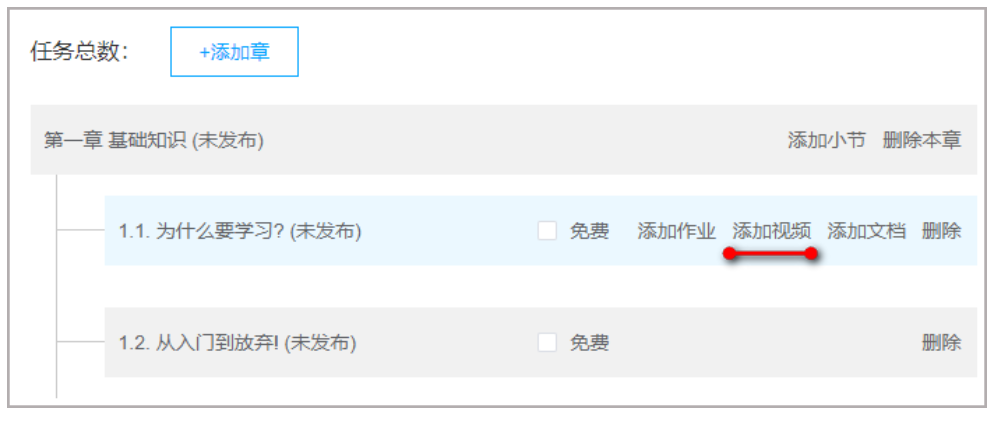

前端流程是：进入课程大纲 → 点击小节后的添加视频 → 搜索媒资 → 选择并提交 → 小节显示视频文件名。

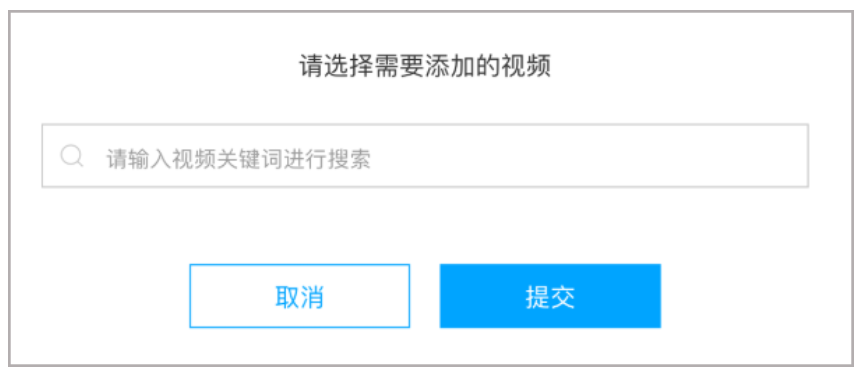

讲义界面以已审核通过的视频为可选资源。后台同样应该验证可用性，不能只相信前端筛选。是否已转码完成、归属机构是否匹配、是否可以播放等检查属于后续需要补齐的业务约束。

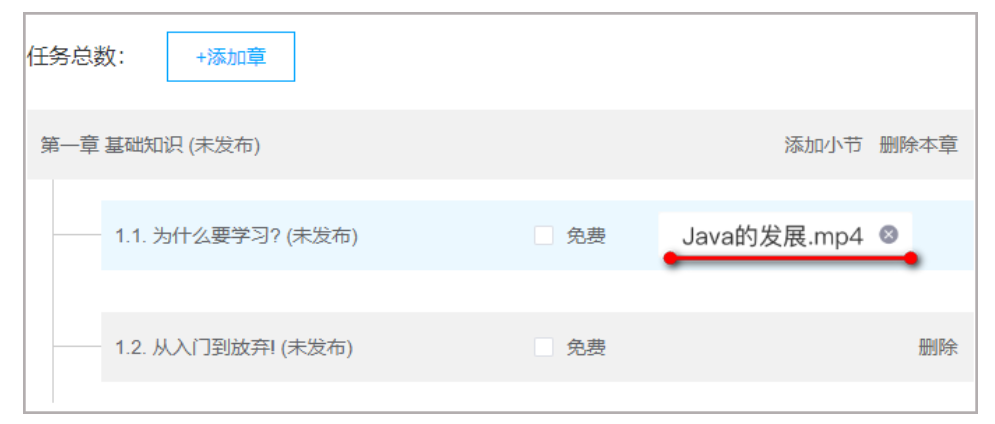

绑定成功不等于发布成功。它修改的是课程编辑数据；课程预览、审核与发布还要使用这些数据进行整合和检查。


## 17. 绑定接口与请求 DTO

绑定属于课程计划业务，所以 Controller 和 Service 位于**内容管理服务**。媒资服务提供文件数据，内容服务维护课程计划与关联关系。

```java
@Data
public class BindTeachplanMediaDto {
    private String mediaId;
    private String fileName;
    private Long teachplanId;
}
```

讲义 Controller 映射为 `/teachplan/association/media`。加上内容服务上下文，对外示例：

```http
POST http://localhost:63040/content/teachplan/association/media
Content-Type: application/json

{
  "mediaId": "70a98b4a2fffc89e50b101f959cc33ca",
  "fileName": "Java的发展.mp4",
  "teachplanId": 257
}
```

`mediaId` 是字符串媒资 ID，`teachplanId` 是 Long 课程计划 ID。示例记录来自讲义，实际测试要使用自己测试环境中确实存在且匹配的数据。

```java
@PostMapping("/teachplan/association/media")
public void associationMedia(@RequestBody BindTeachplanMediaDto dto) {
    teachplanService.associationMedia(dto);
}
```

**补充：**为 DTO 加参数校验，在入口使用 `@Valid`；机构身份从登录上下文取得。`fileName` 是客户端传来的显示字段，不能作为可信媒资元信息，最好由服务端查询媒资后获得。


## 18. 绑定服务与本地事务

讲义的实现先查询课程计划，要求计划存在并且 `grade == 2`，然后取得 `courseId`，删除该计划原有关联，再插入新的 `TeachplanMedia`。

```java
// 课程流程整理；完整项目还需补充归属与媒资可用性校验。
@Transactional
public void associationMedia(BindTeachplanMediaDto dto) {
    Teachplan plan = teachplanMapper.selectById(dto.getTeachplanId());
    if (plan == null) {
        throw new IllegalArgumentException("课程计划不存在");
    }
    if (!Integer.valueOf(2).equals(plan.getGrade())) {
        throw new IllegalArgumentException("只能在课程小节绑定视频");
    }
    teachplanMediaMapper.delete(new LambdaQueryWrapper<TeachplanMedia>()
            .eq(TeachplanMedia::getTeachplanId, plan.getId()));
    TeachplanMedia relation = new TeachplanMedia();
    relation.setCourseId(plan.getCourseId());
    relation.setTeachplanId(plan.getId());
    relation.setMediaId(dto.getMediaId());
    relation.setMediaFilename(dto.getFileName());
    relation.setCreateDate(LocalDateTime.now());
    if (teachplanMediaMapper.insert(relation) != 1) {
        throw new IllegalStateException("绑定视频失败");
    }
}
```

删旧关联和插入新关联必须在一个事务中。插入失败时，事务回滚应恢复原绑定。`courseId` 从查到的计划获取，不应由客户端任意指定。

同一小节重复绑定同一媒资，从业务结果上可以设计为幂等；并发绑定不同媒资则要明确覆盖规则。**补充：**对 `teachplan_id` 建立适当唯一约束，结合计划行锁、版本校验或受控 upsert，防止并发“先删后插”产生两条关系。仅加 `@Transactional` 不能自动解决所有并发覆盖问题。

后台还应检查：计划对应课程属于当前机构；媒资属于允许使用的机构；媒资类型、审核与处理状态符合要求。跨服务读取媒资信息不属于这个本地数据库事务，必要时还要处理读到过期状态的情形。


## 19. 解除绑定的实战题

讲义给出的接口定义：

```http
DELETE http://localhost:63040/content/teachplan/association/media/257/70a98b4a2fffc89e50b101f959cc33ca
```

Controller 方法相对路径为 `/teachplan/association/media/{teachPlanId}/{mediaId}`，成功响应状态为 200。

**讲义校正：**示例 HTTP 把主机和前缀写成了媒资服务的 `media_host/media/...`。该操作维护课程计划关联，应该走内容服务 `/content/...`，不能把绑定接口放到媒资服务。

```java
// 补充的解除绑定核心条件；之前应校验计划和机构归属。
public int removeAssociation(Long teachPlanId, String mediaId) {
    return teachplanMediaMapper.delete(
            new LambdaQueryWrapper<TeachplanMedia>()
                    .eq(TeachplanMedia::getTeachplanId, teachPlanId)
                    .eq(TeachplanMedia::getMediaId, mediaId));
}
```

同时带计划 ID 和媒资 ID 可以防止一个过期界面把后来新绑定的视频也删除。若只按计划 ID 删除，用户原来看到 A，但另一人已经换成 B，旧请求可能误删 B。

解除关联只删除关系记录，不等于删除 MinIO 文件，也不等于删除媒资元信息。视频可能被其他计划引用，文件删除应该由独立的媒资生命周期规则管理。

如果设计重复解除为幂等，更新 0 行也可以作为“关系已经不存在”处理；仍必须先进行权限检查，不能把幂等当作跳过授权的理由。


## 20. 绑定与解除绑定的联调

| 场景 | 应观察的结果 |
| --- | --- |
| 合法小节绑定合法媒资 | 关联表插入，前端刷新后显示文件名 |
| 绑定到章节点 | 根据 `grade` 拒绝，数据库不变 |
| 不存在的计划 | 明确业务错误，不插入孤立关系 |
| 替换视频 A 为 B | 只保留新关联，事务失败则恢复 A |
| 重复绑定 | 不产生多条关系，结果符合约定 |
| 同时绑定两个不同视频 | 唯一约束与并发策略生效 |
| 过期解除请求 | 请求中的旧媒资 ID 不删除新关联 |
| 跨机构或不可用媒资 | 由后台校验拒绝，不能靠前端保证 |
| 解除成功后刷新 | 小节恢复添加视频入口，文件仍在媒资库 |

前端显示名称并不能证明关联正确。需要同时核对请求里的 `teachplanId/mediaId`、关联表中的 `course_id`、课程计划列表响应以及文件真实可播放性。

绑定相关接口的请求首先检查服务端口和 `/content` 前缀；通过网关时再核对网关路由是否按前篇配置保留或重写上下文路径。


## 21. 门户部署的组件与目标

day07 资料目录包含 `nginx-1.23.1.zip`、`nginx.conf.zip`、`xc-ui-pc-static-portal.zip` 和部署门户文档。原文把静态门户、课程详情、文件服务与播放页面分别配置。

```text
浏览器
  ├─ www.51xuecheng.cn → Nginx → 门户 HTML、CSS、JS、图片
  │                         └→ 后续动态接口代理 → 网关 → 内容等服务
  └─ file.51xuecheng.cn → Nginx → MinIO 9000 → mediafiles / video 桶
```

静态页面由 Nginx 从本地前端目录读取；动态课程数据由后台接口提供；文件 URL 指向文件域名，Nginx 将请求转发给 MinIO。这三个路径要分别验证。

讲义的课程预览流程还包括内容服务整合课程数据、FreeMarker 在服务端渲染 HTML。第 07 天先完成页面与播放器基础环境，不应把静态样例打开成功当作完整课程发布完成。

原文用以下学习环境值：

| 项目 | 讲义值 |
| --- | --- |
| Nginx 版本 | `1.23.1` |
| 门户入口 | `http://www.51xuecheng.cn` |
| 文件入口 | `http://file.51xuecheng.cn` |
| MinIO 文件 API | `192.168.101.65:9000` |
| 门户目录 | `D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal` |
| 内容服务入门测试 | `localhost:63040/content/testfreemarker` |

本机目录和虚拟机 IP 应替换为实际环境。`9000` 是文件 API 端口，不要误用 MinIO 控制台端口。


## 22. hosts 与 Nginx 操作流程

讲义要求将本机域名解析到 `127.0.0.1`。Windows 文件为 `C:\Windows\System32\drivers\etc\hosts`；Linux 为 `/etc/hosts`。

```text
127.0.0.1 www.51xuecheng.cn 51xuecheng.cn ucenter.51xuecheng.cn teacher.51xuecheng.cn file.51xuecheng.cn
```

hosts 只解决“域名到 IP”的映射。端口由访问 URL 决定，具体网站由 Nginx 的 `server_name` 选择。把某个域名写进 hosts，不会自动让相应网站有可用服务。

例如浏览器请求 `http://www.51xuecheng.cn`，解析到 `127.0.0.1`，连接本机 80 端口，HTTP Host 仍是 `www.51xuecheng.cn`，Nginx 据此选择主站的 server。

**学习操作示例，未在本机执行：**在自己解压的 Nginx 目录中先验证配置，再启动或重新加载。

```powershell
.\nginx.exe -t
.\nginx.exe
.\nginx.exe -t
.\nginx.exe -s reload
.\nginx.exe -s quit
```

初次启动与运行中 reload 是不同操作。检查 `logs/error.log` 和 `logs/access.log`；看到进程存在只能说明进程启动，仍应访问页面确认所需 server 和路径生效。

讲义通过任务管理器结束进程再双击启动演示。**补充：**常规配置更新优先使用 `-t` 与 `-s reload`，停止时使用优雅退出。80 端口冲突应先确认占用者，再选择调整端口或停止自己明确管理的服务。

如果改为 8080，访问地址必须显式加 `:8080`，门户文件域名和允许的跨域 Origin 也要按实际端口一致配置。hosts 中不能写端口。本次笔记编写没有修改 hosts 或启动任何服务。


## 23. 主站静态资源配置

下方保留门户文档的主站域名、目录映射和 SSI 思路，省略默认 PHP 等无关注释。它是放在 `nginx.conf` 的 `http { ... }` 内的配置片段，不是完整的顶层文件。

```nginx
server {
    listen 80;
    server_name www.51xuecheng.cn localhost;
    ssi on;
    ssi_silent_errors on;

    location / {
        alias D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal/;
        index index.html index.htm;
    }
    location /static/img/ {
        alias D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal/img/;
    }
    location /static/css/ {
        alias D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal/css/;
    }
    location /static/js/ {
        alias D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal/js/;
    }
    location /static/plugins/ {
        alias D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal/plugins/;
        add_header Access-Control-Allow-Origin http://ucenter.51xuecheng.cn;
        add_header Access-Control-Allow-Credentials true;
        add_header Access-Control-Allow-Methods GET;
    }
    location /plugins/ {
        alias D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal/plugins/;
    }
}
```

目录要整体替换，不要只改第一个 `alias`。Windows 下 Nginx 配置使用正斜杠更清楚，带空格的路径需要加引号，路径分号不能遗漏。

资源请求的映射示例：`/static/css/site.css` → 门户目录的 `css/site.css`；`/plugins/player.js` → `plugins/player.js`。前端页面写的 URL 以 `/static/` 开头，但本地 ZIP 中可能是 `css/`、`js/`、`img/` 目录，这正是 `alias` 映射的作用。

访问首页后，打开浏览器 Network 核对 CSS、JS、图片和插件请求。只看到 HTML 200，但样式或脚本 404，说明门户还没有部署完整。


## 24. alias、root、SSI 与跨域

`root` 把完整 URI 附加到目录；`alias` 用给定目录替换匹配的 location 前缀。

| 配置意图 | 请求 | 实际文件 |
| --- | --- | --- |
| `location /course/` 内设置 `root D:/portal` | `/course/learning.html` | `D:/portal/course/learning.html` |
| `location /static/css/` 内设置 `alias D:/portal/css/` | `/static/css/site.css` | `D:/portal/css/site.css` |

如果给 `root` 写成 `D:/portal/course`，URI 又带 `/course/`，就可能拼成 `D:/portal/course/course/...`。目录型 `alias` 与 location 的尾斜杠通常要对应；将一个固定 URL 映射到单个文件时，可以使用精确匹配和文件型 alias。

**SSI 是 Nginx 对 HTML 的服务器端包含处理。**门户可能用它组合公共页头、页尾等片段。文档配置 `ssi on` 和 `ssi_silent_errors on`；后者可能隐藏包含失败提示，排错时还要看日志和最终页面内容。SSI 不会替代 Java 服务里的 FreeMarker 业务模板渲染。

文档仅在 `/static/plugins/` 处为 `http://ucenter.51xuecheng.cn` 添加跨域头。跨域由协议、主机和端口共同决定；同属 `51xuecheng.cn` 的不同子域仍可能跨域。

不要把这组静态插件跨域配置理解为后台 API 已全部允许跨域。带凭据的跨域请求不能把 `Access-Control-Allow-Origin` 随意改为 `*`；预检、Cookie 与各 API 的行为应另按实际需求配置。


## 25. 课程详情和播放页面

文档中的课程详情样例是 `xc-ui-pc-static-portal/course/course_template.html`，当时还是普通 HTML，没有完整 FreeMarker 数据绑定。

访问地址为：

```text
http://www.51xuecheng.cn/course/course_template.html
```

从详情页点击“马上学习”或课程目录小节，进入 `learning.html`。原文还将课程预览 URL 映射到同一播放页面，并给出搜索页面与普通学习页面映射。

```nginx
# 放在主站 server 内；精确匹配是本篇的补充收紧。
location = /course/preview/learning.html {
    alias D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal/course/learning.html;
}
location = /course/search.html {
    root D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal;
}
location = /course/learning.html {
    root D:/itcast2022/xc_edu3.0/code_1/xc-ui-pc-static-portal;
}
```

第一个请求 URI 多了 `/preview/`，而本地文件没有这一层，所以用文件型 `alias`；后两个 URI 与文件目录结构一致，用 `root` 拼接即可。原文使用普通前缀 location，本篇用 `=` 表示只映射准确的页面路径。

不能直接通过本地 `file:///...` 双击页面来代替 Nginx 联调。页面中的绝对资源 URL、SSI、后续接口和跨域行为都依赖 HTTP 环境。

此时详情页展示静态样例，只能证明模板外观和资源加载正常；让不同课程返回各自真实信息，需要后续内容服务聚合数据与模板渲染。


## 26. 文件域名代理 MinIO

图片与视频位于 MinIO。文档给出的文件服务上游和两个桶路径如下，同样应置于 `http` 块内：

```nginx
upstream fileserver {
    server 192.168.101.65:9000 weight=10;
}

server {
    listen 80;
    server_name file.51xuecheng.cn;

    location /video {
        proxy_pass http://fileserver;
    }
    location /mediafiles {
        proxy_pass http://fileserver;
    }
}
```

前篇 Nacos 配置的视频桶是 `video`，普通媒资桶是 `mediafiles`。文档使用这两个路径与其对应。上游只有一台服务器时，`weight=10` 不会让它拥有额外副本，也不代表有 10 个实例。

**关键：**这里 `proxy_pass http://fileserver;` 没有带 URI，通常会将原请求路径继续传给上游。

```text
浏览器：http://file.51xuecheng.cn/video/a/b/{fileId}/{fileId}.mp4
上游：  http://192.168.101.65:9000/video/a/b/{fileId}/{fileId}.mp4
                                             ↑
                                          桶名仍保留
```

若改成 `location /video/ { proxy_pass http://fileserver/; }`，由于上游 URL 带了 `/` 这个 URI，匹配前缀会被替换，可能把桶名 `/video/` 去掉而请求失败。不能为了“统一斜杠”随意改变这段配置。

数据库中的相对播放地址若为 `/video/...mp4`，浏览器应使用文件域名加上它，避免重复拼桶名，例如不要变成 `/video/video/...`。图片测试也应读取真实的 `media_files.url`，不能只凭空构造对象 key。

上述代理不会自动给予对象访问权限。私有桶仍可能返回 403；应使用现有允许的访问策略或由服务端产生受控的签名访问地址。后续鉴权方案要按项目设计配置。


## 27. learning.html 的播放验证

文档要求在 `learning.html` 找到 `videoObject` 定义，将它的播放地址设置为可访问的 MP4，再刷新页面测试。播放器对象的其他配置应保留原页面内容。

```javascript
// 补充示意：只展示应替换的播放字段，不重建整个播放器对象。
videoObject.video = 'http://file.51xuecheng.cn/video/a/b/源文件ID/源文件ID.mp4';
```

将示意地址替换为数据库实际记录的 URL；如果页面是在创建播放器之前声明配置，应直接修改原对象中的播放字段，再按页面原来的初始化顺序运行。不能先创建播放器后只改变量，就假定播放器必然重新加载。

验证顺序：先单独访问真实 MP4 地址，确认能取得文件；再打开播放页，核对插件 JS 和 CSS；最后测试开始播放、声音、暂停和拖动进度。

视频拖动常涉及 HTTP Range 请求。Network 中观察 `Range`、`206 Partial Content` 与 `Content-Range` 是否符合请求，不应只看首页 200。服务端或代理若错误处理范围请求，可能出现能开始播放却不能拖动的现象。

`Content-Type` 应是 `video/mp4`。有文件数据但不能解码时，再检查内部编码与像素格式；页面本身空白时先看 Console 和插件资源。浏览器的自动播放限制也可能要求用户点击播放，不能据此直接判定文件损坏。

原文明确说明：播放页此时还会请求后台课程计划接口，**这一阶段暂不处理**，稍后再开发。课程计划列表暂时报错与测试视频是否可播放需要分开判断；本日验收是页面能打开且视频能播放。


## 28. FreeMarker 入门与后续课程预览

门户文档先介绍课程预览、审核和发布，再提供 FreeMarker 入门。其作用是把课程数据填进模板，让每个课程得到对应的 HTML。

```text
HTML 模板 + 课程数据模型 → FreeMarker 渲染 → 课程详情 HTML
```

内容 API 工程加入 Spring Boot 整合依赖，版本由项目的依赖管理决定：

```xml
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-freemarker</artifactId>
</dependency>
```

原文在 Nacos 公用配置组新增 `freemarker-config-dev.yaml`，让内容 API 工程引用该配置。以下核心项与文档一致：

```yaml
spring:
  freemarker:
    enabled: true
    cache: false
    settings:
      template_update_delay: 0
    suffix: .ftl
    charset: UTF-8
    template-loader-path: classpath:/templates/
```

原文还使用 `spring.resources.add-mappings: false` 关闭 Spring 静态资源映射，让静态资源走门户 Nginx。配置属性应以实际 Spring Boot 版本为准，较新版本常使用 `spring.web.resources.add-mappings`；不要把两个路径同时堆进去猜哪个生效。关闭静态映射与开启模板渲染是不同设置。

在 `src/main/resources/templates/test.ftl` 添加入门模板：

```html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
    <meta charset="utf-8">
    <title>FreeMarker 入门</title>
</head>
<body>Hello ${name}!</body>
</html>
```

Controller 使用 `@Controller`，通过 `ModelAndView` 指定模型和模板名：

```java
@Controller
public class FreemarkerController {
    @GetMapping("/testfreemarker")
    public ModelAndView test() {
        ModelAndView view = new ModelAndView();
        view.addObject("name", "小明");
        view.setViewName("test");
        return view;
    }
}
```

测试地址为 `http://localhost:63040/content/testfreemarker`，原文预期输出 `Hello 小明！`；此处模板使用英文感叹号，展示为 `Hello 小明!`。`test` 加上 `.ftl` 后缀对应模板文件。不要误用 `@RestController` 直接返回模板名称字符串，这会把字符串当响应正文。

开发时关闭模板缓存便于修改，生产环境应按实际更新策略配置缓存。正式课程模板还要处理空值、列表、日期、HTML 转义与可信内容范围；本篇不把入门测试扩展成已经完成课程预览接口。


## 29. 从上传到播放的完整排错顺序

先确认在哪一层失败，再进入该层检查，避免同时修改网关、任务和门户配置。

| 现象 | 优先检查 |
| --- | --- |
| AVI 上传完成却没有任务 | 入库事务、MIME 判断、活动任务唯一索引、是否已成功处理 |
| 执行器查询不到任务 | 分片参数、状态、失败次数、实际数据源与 Mapper SQL |
| 查询到但没有处理 | `startTask` 返回行数，是否已被其他线程认领 |
| 长期 `status=4` | worker 异常、结果事务失败、进程超时、租约补偿是否存在 |
| MP4 上传后活动任务仍在 | 成功事务是否提交，历史表约束及各操作行数 |
| 转码成功却播放器报错 | 输出内部编码、文件完整性、Content-Type 与实际播放 URL |
| 门户显示默认 Nginx 页面 | 请求 Host、server_name、端口、配置是否真的加载 |
| HTML 有内容但样式缺失 | `/static/` 的 alias 路径、ZIP 解压层级、CSS/JS 404 |
| `learning.html` 404 | 预览路径与普通路径的 alias/root 映射 |
| 文件域名返回 502 | Nginx 到 MinIO 的 IP、9000 端口和网络连通性 |
| 文件返回 404 | 桶名、对象 key、proxy_pass 是否改写 URI |
| 文件返回 403 | 对象访问方式和签名/权限，不先归因于转码 |
| 视频能播放不能拖动 | Range 与 206 响应、代理行为、文件索引 |
| 绑定接口 404 | 内容服务端口、`/content` 前缀、网关路由 |
| 绑定显示不一致 | 真实计划 ID、关联表、返回 DTO、前端刷新与并发覆盖 |

当天联调完成后，应能串起这些证据：源对象存在 → 活动任务创建 → 唯一认领 → MP4 生成并上传 → URL 更新与成功归档 → 小节关联正确 → 门户静态资源正常 → 文件域名可访问 → 浏览器实际播放。

本篇代码与配置只做静态整理；上表和第 15、20 节用于你运行项目时逐项验证，不代表这些运行实验已经通过。


## 30. 复习与面试表达

**为什么异步转码？**转码耗时长且消耗 CPU，把它留在上传接口会占用请求线程并增加超时。上传成功后把业务任务持久化，由 XXL-JOB 调度的执行器处理，失败可以追踪和重试。

**怎样避免多个执行器处理同一任务？**先按任务 ID 取模分片查询，再使用带状态条件的原子 UPDATE 将 `1/3` 改为 `4`，更新行数为 1 才取得执行权。分片负责分工，条件更新负责认领。

**能保证严格只处理一次吗？**仅有分片与状态字段不能保证。进程崩溃、调度重复、超时后旧线程迟到都可能造成重试，需要幂等结果提交、租约/执行令牌和对象写入约束。应分别解释“计算可能重复”和“业务结果避免重复生效”。

**数据库事务为什么不能回滚 MinIO 上传？**本地事务只覆盖同一数据库资源。对象上传与任务结果提交之间存在失败窗口，要用可重试的对象写入和业务补偿保证最终一致。

**为什么只在小节绑定媒资？**课程计划中的章是目录容器，小节才对应具体学习内容。课程校验 `grade=2`，把真实 `courseId`、计划 ID 和媒资 ID 存入关联表。

**为什么解除绑定不删视频？**解除改变计划与视频的关系；视频对象仍可能被其他小节引用，不能用解除接口替代媒资删除。

**Nginx 和网关各做什么？**Nginx 为浏览器提供门户静态资源和统一文件域名；网关管理后端微服务入口。Nginx 可以代理动态接口，但配置静态站点并不自动完成网关路由。

**root、alias 和 proxy_pass 怎么区分？**root 用完整 URI 拼本地目录；alias 替换匹配前缀；proxy_pass 将请求转发给上游，带不带 URI 会影响路径替换。本日 MinIO 代理需要保留 `/video` 或 `/mediafiles` 桶名。

**今天应该记住的代码问题：**空列表不能用 `size < 0`；等待超时不自动停止转码；失败上限以 `fail_count < 3` 为准；认领和结果提交都需要条件；上传时间不能当执行开始时间；成功只更新播放 URL 时，源文件摘要不会变成结果摘要；绑定和解绑要走内容服务。

下一篇进入课程预览、审核与发布：把已有课程基础信息、营销信息、计划和媒资整合到模板中，并继续处理发布后的数据同步与一致性。
